In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA

# 1. Load the benchmark dataset using Pandas
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

# Display the first few rows to verify
display(df.head())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Figure size 1000x800 with 0 Axes>

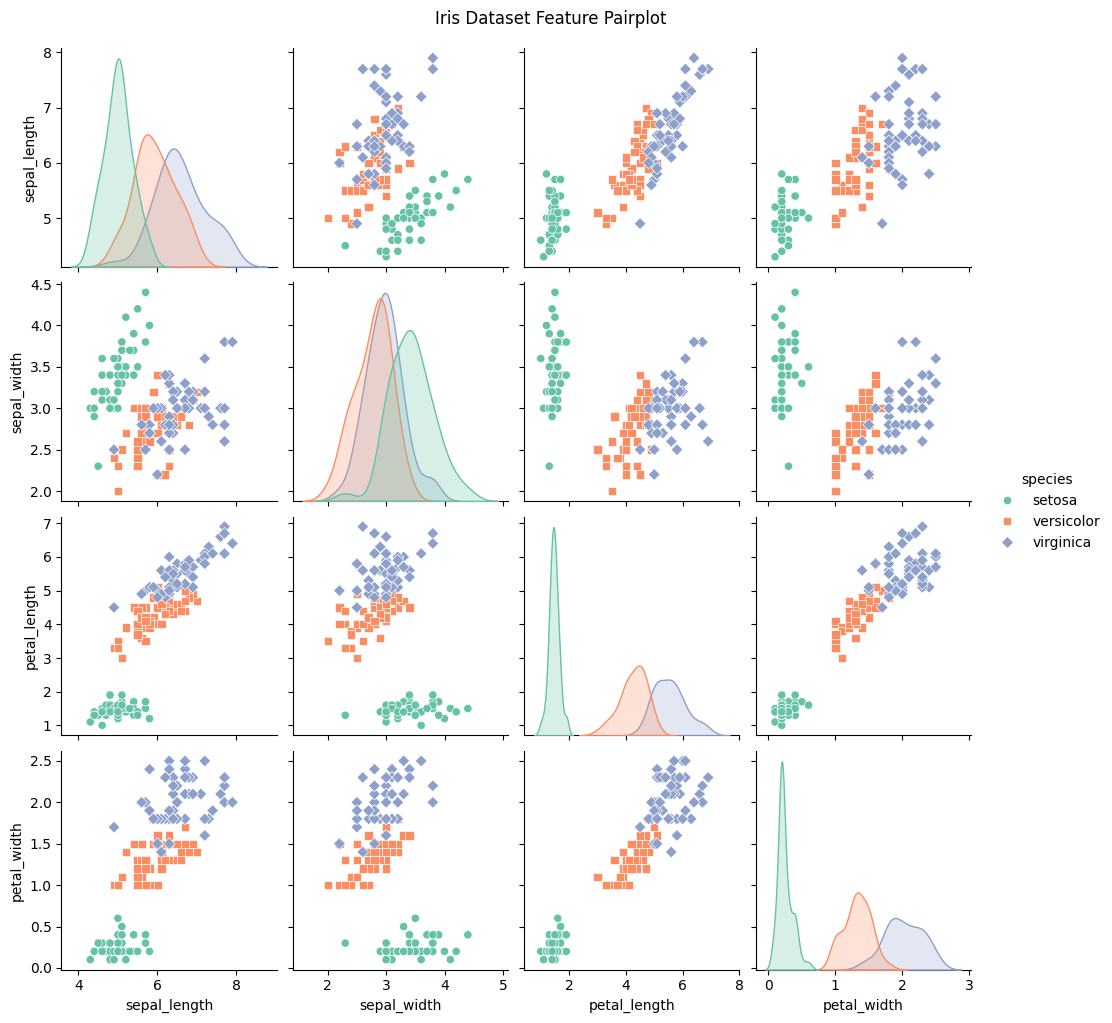

In [3]:
# 2. Perform exploratory pairplots with Seaborn
plt.figure(figsize=(10, 8))
sns.pairplot(df, hue='species', palette='Set2', markers=["o", "s", "D"])
plt.suptitle("Iris Dataset Feature Pairplot", y=1.02)
plt.show()

In [4]:
# Separate features (X) and target labels (y)
X = df.drop('species', axis=1)
y = df['species']

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Normalize features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training data shape: {X_train_scaled.shape}")
print(f"Testing data shape: {X_test_scaled.shape}")

Training data shape: (120, 4)
Testing data shape: (30, 4)


In [5]:
# 4. Train LogisticRegression and DecisionTreeClassifier
# Logistic Regression
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

# Decision Tree Classifier
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train_scaled, y_train)
y_pred_tree = tree_clf.predict(X_test_scaled)

# Benchmark Metrics
print("--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_lr))

print("\n--- Decision Tree Classification Report ---")
print(classification_report(y_test, y_pred_tree))

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


--- Decision Tree Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



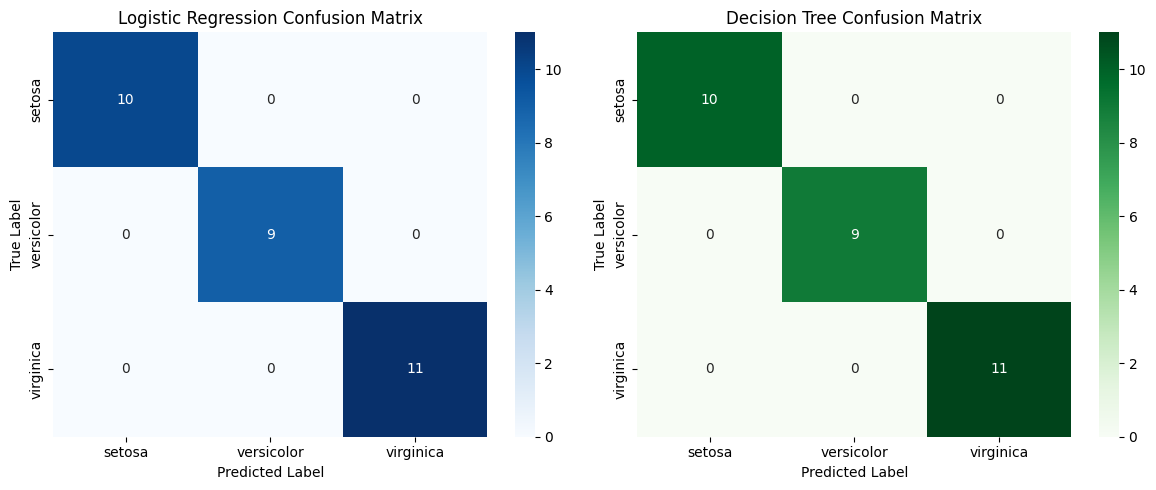

/Users/harryprasath/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/harryprasath/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/harryprasath/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


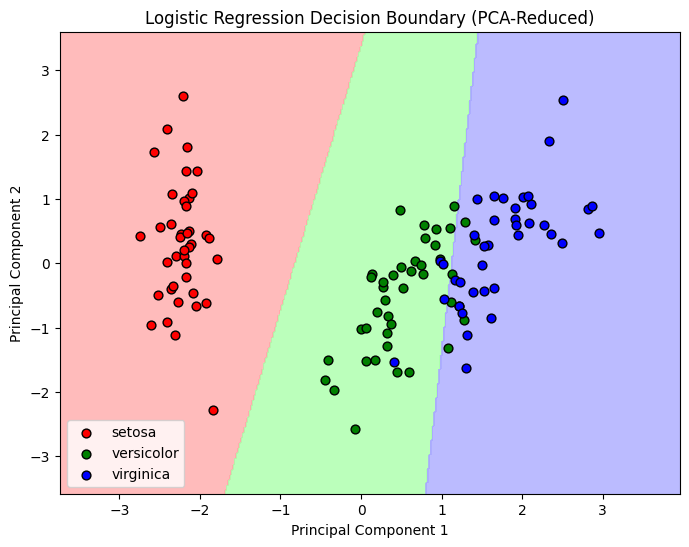

In [6]:
# 5a. Plot the confusion matrix heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, cmap='Blues', ax=axes[0], 
            xticklabels=log_reg.classes_, yticklabels=log_reg.classes_)
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(confusion_matrix(y_test, y_pred_tree), annot=True, cmap='Greens', ax=axes[1], 
            xticklabels=tree_clf.classes_, yticklabels=tree_clf.classes_)
axes[1].set_title('Decision Tree Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

# 5b. Plot the decision boundary visualization (Using PCA for 2D visualization)
# Reduce data to 2 dimensions for plotting
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Re-train models on the 2D data purely for visualization purposes
log_reg_pca = LogisticRegression(random_state=42).fit(X_train_pca, y_train)

# Map string labels to integers for plotting contours
target_names = df['species'].unique()
y_train_int = y_train.map({target_names[0]: 0, target_names[1]: 1, target_names[2]: 2})

# Setup grid for plotting
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# Predict across the grid
Z = log_reg_pca.predict(np.c_[xx.ravel(), yy.ravel()])
Z_int = np.array([np.where(target_names == z)[0][0] for z in Z])
Z_int = Z_int.reshape(xx.shape)

# Plot
plt.figure(figsize=(8, 6))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ['red', 'green', 'blue']

plt.contourf(xx, yy, Z_int, cmap=cmap_light, alpha=0.8)
for i, color in zip(range(3), cmap_bold):
    idx = np.where(y_train_int == i)
    plt.scatter(X_train_pca[idx, 0], X_train_pca[idx, 1], c=color, 
                label=target_names[i], edgecolor='black', s=40)

plt.title("Logistic Regression Decision Boundary (PCA-Reduced)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()